# 11a Uncertainty

A point forecast says "about 12 tomorrow". A stock decision also needs to know how wrong that could be. In 09a we
made a simple 90% band from each product's own past errors, and it held the actual sales on only 84.5% of days. Here
we check that band origin by origin and build a better one with split conformal prediction: pool the past errors of
all products in a category (each scaled by the product's MASE scale, so big and small sellers can share), and take
the quantile that should cover 90%, with the small-sample correction. 11c turns these bands into safety stock.

## Load

In [1]:
import sys, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import ROOT, RAW, INTERIM, PROCESSED, TABLES, FIGS, FIG_STYLE
from break_detection import weekly_ca_prices
from metrics import paired_test
from pipeline import price_daily_frame, simulate_inventory, summarise_inventory, intermittency

SEED = 42
plt.rcParams.update(FIG_STYLE)
written = []
fc = pd.read_parquet(PROCESSED / "backtest_forecasts.parquet")
err = pd.read_csv(PROCESSED / "backtest_errors.csv", parse_dates=["origin"])
scales = err[["item_id", "origin", "mase_scale"]].drop_duplicates()
ORIGINS = sorted(fc["origin"].unique())
EVAL = ORIGINS[1:]
fc["category"] = fc["item_id"].str.split("_").str[0]

POL = [("lightgbm", "static"), ("lightgbm", "adaptive"), ("seasonal_naive", "static")]
f = fc[fc.set_index(["model", "variant"]).index.isin(POL)].merge(scales, on=["item_id", "origin"])
f["e"] = f["actual"] - f["forecast"]
f["r"] = f["e"] / f["mase_scale"]          # errors in units of each product's own MASE scale, so products can be pooled
print(len(ORIGINS), "origins;", f"{len(f):,} forecast days for", POL)

7 origins; 426,888 forecast days for [('lightgbm', 'static'), ('lightgbm', 'adaptive'), ('seasonal_naive', 'static')]


## Coverage before and after

In [2]:
def conformal_offsets(r, alpha):
    """Lower and upper quantile of pooled scaled errors, with the finite-sample correction."""
    r = np.asarray(r)
    n = len(r)
    level = min(1.0, np.ceil((n + 1) * (1 - alpha / 2)) / n)
    return -np.quantile(-r, level, method="higher"), np.quantile(r, level, method="higher")

rows = []
for (model, variant), g in f.groupby(["model", "variant"]):
    for k, origin in enumerate(EVAL, start=1):
        test = g[g["origin"] == origin]
        for alpha in [0.2, 0.1]:
            lvl = int(round(100 * (1 - alpha)))
            # before: each product's own error quantiles from earlier origins
            past = g[g["origin"] < origin].groupby("item_id")["e"]
            q = past.quantile([alpha / 2, 1 - alpha / 2]).unstack()
            t = test.join(q, on="item_id")
            lo = np.maximum(t["forecast"] + t[alpha / 2], 0)
            hi = t["forecast"] + t[1 - alpha / 2]
            inside_b = (t["actual"] >= lo) & (t["actual"] <= hi)
            # after: category-pooled, scaled conformal
            inside_a = pd.Series(False, index=test.index)
            width_a = pd.Series(np.nan, index=test.index)
            for cat, tc in test.groupby("category"):
                pool = g[(g["origin"] < origin) & (g["category"] == cat)]["r"]
                qlo, qhi = conformal_offsets(pool, alpha)
                lo_a = np.maximum(tc["forecast"] + qlo * tc["mase_scale"], 0)
                hi_a = tc["forecast"] + qhi * tc["mase_scale"]
                inside_a.loc[tc.index] = (tc["actual"] >= lo_a) & (tc["actual"] <= hi_a)
                width_a.loc[tc.index] = hi_a - lo_a
            rows.append({"model": model, "variant": variant, "origin_index": k, "origin": origin, "level": lvl,
                         "n_days": len(test), "coverage_before": inside_b.mean(), "coverage_after": inside_a.mean(),
                         "mean_width_before": (hi - lo).mean(), "mean_width_after": width_a.mean()})
cov = pd.DataFrame(rows)
cov.to_csv(TABLES / "conformal_coverage_by_origin.csv", index=False)
cov["origins"] = np.where(cov["origin_index"] == 1, "origin 1 (warm-up only)", "origins 2-6")
cs = cov.groupby(["model", "variant", "level", "origins"]).apply(
    lambda d: pd.Series({"n_days": d["n_days"].sum(),
                         "coverage_before": np.average(d["coverage_before"], weights=d["n_days"]),
                         "coverage_after": np.average(d["coverage_after"], weights=d["n_days"]),
                         "mean_width_before": np.average(d["mean_width_before"], weights=d["n_days"]),
                         "mean_width_after": np.average(d["mean_width_after"], weights=d["n_days"])}),
    include_groups=False).reset_index()
cs["within_2pts_after"] = (cs["coverage_after"] - cs["level"] / 100).abs() <= 0.02
cs.to_csv(TABLES / "conformal_coverage.csv", index=False)
written += [TABLES / "conformal_coverage_by_origin.csv", TABLES / "conformal_coverage.csv"]
cs.round(4)

,model,variant,level,origins,n_days,coverage_before,coverage_after,mean_width_before,mean_width_after,within_2pts_after
0,lightgbm,adaptive,80,origin 1 (warm-up only),20328.0,0.6772,0.7962,13.0160,15.6280,True
1,lightgbm,adaptive,80,origins 2-6,101640.0,0.7554,0.7970,15.3243,16.6625,True
2,lightgbm,adaptive,90,origin 1 (warm-up only),20328.0,0.7839,0.8920,16.5128,20.7954,True
3,lightgbm,adaptive,90,origins 2-6,101640.0,0.8532,0.8976,19.8344,22.4348,True
4,lightgbm,static,80,origin 1 (warm-up only),20328.0,0.6901,0.7948,12.9645,15.5653,True
5,lightgbm,static,80,origins 2-6,101640.0,0.7561,0.7975,15.1792,16.4444,True
6,lightgbm,static,90,origin 1 (warm-up only),20328.0,0.7906,0.8927,16.4967,20.7277,True
7,lightgbm,static,90,origins 2-6,101640.0,0.8555,0.8992,19.7172,22.1480,True
8,seasonal_naive,static,80,origin 1 (warm-up only),20328.0,0.6981,0.7683,15.2485,18.1139,False
9,seasonal_naive,static,80,origins 2-6,101640.0,0.7827,0.8055,18.2859,19.5118,True


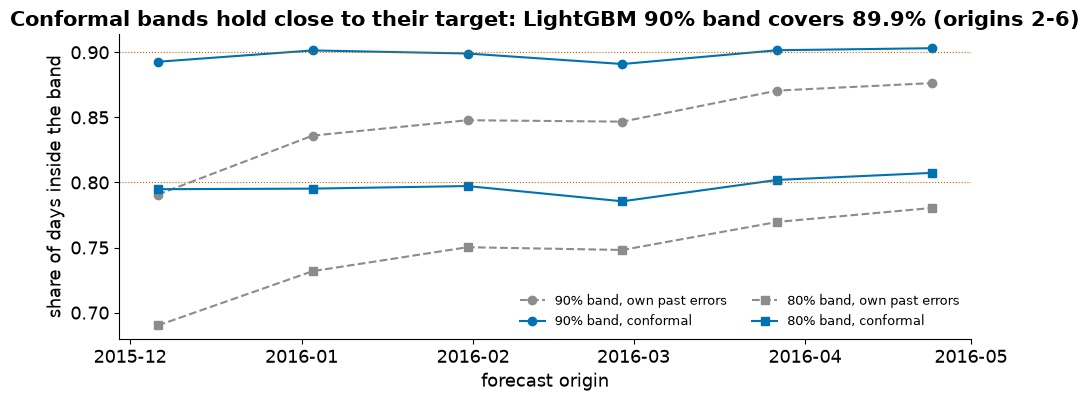

In [3]:
x = cov[(cov["model"] == "lightgbm") & (cov["variant"] == "static")]
fig, ax = plt.subplots(figsize=(10, 4.2))
for lvl, mk in [(90, "o"), (80, "s")]:
    d = x[x["level"] == lvl]
    ax.plot(d["origin"], d["coverage_before"], marker=mk, ls="--", color="#8C8C8C", label=f"{lvl}% band, own past errors")
    ax.plot(d["origin"], d["coverage_after"], marker=mk, color="#0072B2", label=f"{lvl}% band, conformal")
    ax.axhline(lvl / 100, color="#D55E00", lw=0.8, ls=":")
ax.set_xlabel("forecast origin")
ax.set_ylabel("share of days inside the band")
after90 = cs[(cs["model"] == "lightgbm") & (cs["variant"] == "static") & (cs["level"] == 90) & (cs["origins"] == "origins 2-6")]
ax.set_title(f"Conformal bands hold close to their target: LightGBM 90% band covers {after90['coverage_after'].iloc[0]:.1%} (origins 2-6)")
ax.legend(frameon=False, fontsize=9, ncol=2)
fig.tight_layout()
fig.savefig(FIGS / "conformal_coverage.png")
written.append(FIGS / "conformal_coverage.png")
plt.show()

## Coverage per product

The same comparison for each product, origins 2 to 6, for the dashboard.

In [4]:
rows = []
for (model, variant), g in f.groupby(["model", "variant"]):
    for origin in EVAL[1:]:
        test = g[g["origin"] == origin]
        past = g[g["origin"] < origin]
        q = past.groupby("item_id")["e"].quantile([0.05, 0.95]).unstack()
        t = test.join(q, on="item_id")
        before = (t["actual"] >= np.maximum(t["forecast"] + t[0.05], 0)) & (t["actual"] <= t["forecast"] + t[0.95])
        after = pd.Series(False, index=test.index)
        for cat, tc in test.groupby("category"):
            qlo, qhi = conformal_offsets(past[past["category"] == cat]["r"], 0.1)
            after.loc[tc.index] = (tc["actual"] >= np.maximum(tc["forecast"] + qlo * tc["mase_scale"], 0)) & \
                                  (tc["actual"] <= tc["forecast"] + qhi * tc["mase_scale"])
        rows.append(pd.DataFrame({"item_id": test["item_id"], "model": model, "variant": variant,
                                  "inside_before": before.to_numpy(), "inside_after": after.to_numpy()}))
cov_items = pd.concat(rows).groupby(["item_id", "model", "variant"], as_index=False).agg(
    n_days=("inside_before", "size"), coverage90_before=("inside_before", "mean"), coverage90_after=("inside_after", "mean"))
cov_items.to_csv(TABLES / "item_band_coverage.csv", index=False)
written.append(TABLES / "item_band_coverage.csv")
chk = cov_items[(cov_items["model"] == "lightgbm") & (cov_items["variant"] == "static")]
print("LightGBM static 90% coverage, origins 2-6 (should match the table above):",
      round(np.average(chk["coverage90_before"], weights=chk["n_days"]), 4), round(np.average(chk["coverage90_after"], weights=chk["n_days"]), 4))

LightGBM static 90% coverage, origins 2-6 (should match the table above): 0.8555 0.8992


## What we found

The simple band was too narrow. For LightGBM its 90% band covered 85.5% of days on origins 2 to 6, and its 80% band
75.6%. The first scored origin is worse still (79%), because at that point the band has only the warm-up origin's
errors to learn from. Each product has just a few hundred past errors, so its own extreme quantiles are noisy and
usually too tight.

Pooling the scaled errors within a category fixes that. The conformal 90% band covers 89.9% and the 80% band 79.8%,
both within a point of their target, and even the first scored origin lands at 89.3%. The price is width: the 90%
band is about 12% wider on average. Seasonal naive behaves the same way. Since the textbook safety-stock formula
assumes errors that are normal and independent, and 07b showed they are neither, this is the band we trust.

## What comes next

`11b_inventory_simulation` runs the stock simulation with the textbook safety stock, and `11c_calibrated_safety_stock` repeats it with these bands.

In [5]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\tables\conformal_coverage_by_origin.csv 4 KB
outputs\tables\conformal_coverage.csv 2 KB
outputs\figures\conformal_coverage.png 84 KB
outputs\tables\item_band_coverage.csv 155 KB
